# Project 2 — Reverse DCF: is Rheinmetall priced for perfection?
Runs `src/model.py` (reproduced with formulas in `model/rheinmetall_reverse_dcf.xlsx`, checked by `src/check_workbook.py`)
and draws the charts used in the memo.

In [1]:
import json
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path[:0] = [str(ROOT), str(ROOT.parent)]

import numpy as np
import pandas as pd

from common.plotting import PALETTE, setup, source
from src import model as M
from src import peers as PE

plt = setup()
DATA, FIG = ROOT / "data", ROOT / "report" / "figures"
FIG.mkdir(parents=True, exist_ok=True)
R = M.run()
mk = R["mk"]
pd.Series(mk).round(4)

/usr/local/lib/python3.13/dist-packages/openpyxl/worksheet/_reader.py:329: UserWarning: Unknown extension is not supported and will be removed
  warn(msg)


rf                0.0355
erp               0.0420
beta_raw          0.4014
beta_se           0.5335
beta_r2           0.0097
beta_blume        0.5989
ke                0.0607
bond_price       96.6000
kd                0.0419
accrued           1.2390
tax               0.2532
price           926.2000
shares_m         46.6557
mcap          43212.5275
debt           3273.0000
w_e               0.9296
wacc              0.0586
dtype: float64

In [2]:
print(f"(a) implied CAGR {R['a_cagr']:.2%} -> 2035 sales EUR {R['a_sales_2035']:,.0f}m; (b) implied margin {R['b_margin']:.2%}")
print({n: round(v["per_share"], 0) for n, v in R["case_val"].items()}, "WACC that equates each case to the price:",
      {n: round(v, 4) for n, v in R["implied_wacc"].items()})
R["wacc_sens"].round(3)

(a) implied CAGR 3.98% -> 2035 sales EUR 14,673m; (b) implied margin 5.07%
{'Bear': np.float64(1948.0), 'Base': np.float64(3220.0), 'Bull': np.float64(4577.0)} WACC that equates each case to the price: {'Bear': 0.0931, 'Base': 0.1292, 'Bull': 0.1623}


,implied CAGR 2025-35 (20% margin),implied 2035 sales (EUR m),implied margin (mgmt sales path),Bear value/share,Base value/share,Bull value/share
0.0586,0.040,14673.343,0.051,1948.277,3219.849,4576.713
0.0700,0.073,20175.550,0.066,1450.534,2396.690,3405.385
0.0800,0.099,25570.694,0.080,1172.459,1936.916,2751.222
0.0900,0.123,31562.226,0.094,975.607,1611.525,2288.327
0.1000,0.144,38210.655,0.108,829.375,1369.885,1944.639
0.1100,0.165,45579.754,0.124,716.775,1183.893,1680.155
0.1200,0.184,53737.179,0.139,627.625,1036.702,1470.899


In [3]:
H = M.history()
H.loc["Book-to-bill"] = H.loc["Rheinmetall Nomination"] / H.loc["Sales"]
H.loc["Operating margin"] = H.loc["Operating result"] / H.loc["Sales"]
H.round(3)

,2019,2020,2021,2022,2023,2024,2025
Sales,6255.000,5405.000,5658.000,6410.000,7176.000,7715.000,9935.000
Equity,2272.000,2053.000,2620.000,3090.000,3643.000,4465.000,5614.000
Operating result,505.000,446.000,594.000,769.000,918.000,1389.000,1841.000
EBIT,512.000,398.000,608.000,738.000,897.000,1270.000,1684.000
Net liquidity (+)/net financial debt (-),-52.000,4.000,118.000,-426.000,-1063.000,-1292.000,369.000
ROCE %,15.400,11.800,19.500,21.400,21.400,25.700,33.500
Share price (31 Dec),102.400,86.580,83.060,186.050,287.000,614.600,1561.000
Order intake,NaN,NaN,NaN,5629.000,11843.000,16554.000,19867.000
Rheinmetall Nomination,NaN,NaN,NaN,9500.000,19881.000,24335.000,26448.000
Rheinmetall Backlog,NaN,NaN,NaN,26572.000,38290.000,46943.000,63761.000


In [4]:
PM = PE.margins()
PEERSTAT = pd.DataFrame({"5-yr average 2021–25": PM[[2021, 2022, 2023, 2024, 2025]].mean(axis=1),
                         "Best year 2021–25": PM[[2021, 2022, 2023, 2024, 2025]].max(axis=1),
                         "Consensus 2028": PM[2028]})
PEERSTAT.round(3)

,5-yr average 2021–25,Best year 2021–25,Consensus 2028
company,,,
BAE Systems,0.106,0.108,0.115
Kongsberg Gruppen,0.123,0.159,0.187
Leonardo,0.084,0.090,0.111
Rheinmetall,0.131,0.170,0.202
Saab,0.085,0.102,0.115
Thales,0.114,0.124,0.135


## Charts

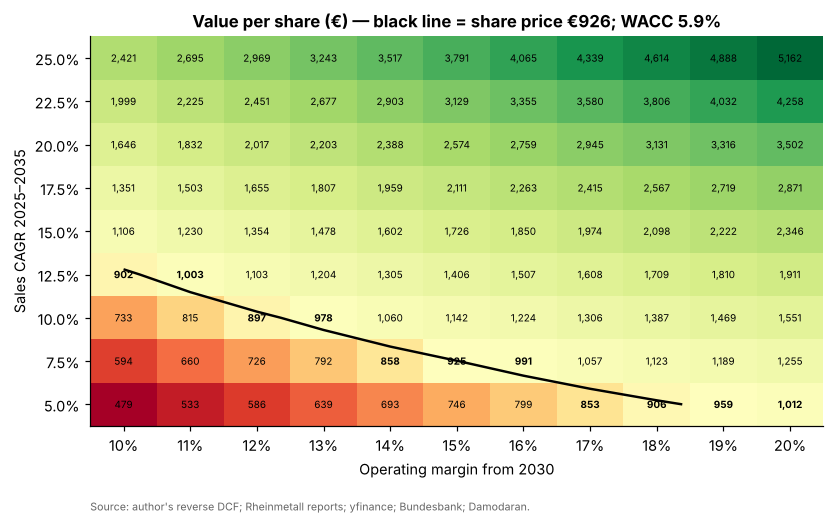

In [5]:
g = R["grid"]
fig, ax = plt.subplots(figsize=(8.6, 4.6))
im = ax.imshow(g.values, cmap="RdYlGn", aspect="auto", origin="lower",
               norm=__import__("matplotlib").colors.TwoSlopeNorm(vcenter=mk["price"], vmin=g.values.min(), vmax=g.values.max()))
ax.set_xticks(range(len(g.columns)), [f"{c:.0%}" for c in g.columns]); ax.set_yticks(range(len(g.index)), [f"{c:.1%}" for c in g.index])
for i in range(g.shape[0]):
    for j in range(g.shape[1]):
        v = g.values[i, j]
        ax.text(j, i, f"{v:,.0f}", ha="center", va="center", fontsize=6.5, fontweight="bold" if abs(v / mk["price"] - 1) <= 0.1 else "normal")
cs = ax.contour(g.values, levels=[mk["price"]], colors="black", linewidths=1.6)
ax.set_xlabel("Operating margin from 2030"); ax.set_ylabel("Sales CAGR 2025–2035")
ax.set_title(f"Value per share (€) — black line = share price €{mk['price']:,.0f}; WACC {mk['wacc']:.1%}")
ax.grid(False)
source(ax, "Source: author's reverse DCF; Rheinmetall reports; yfinance; Bundesbank; Damodaran.")
fig.savefig(FIG / "fig_grid.png"); plt.show()

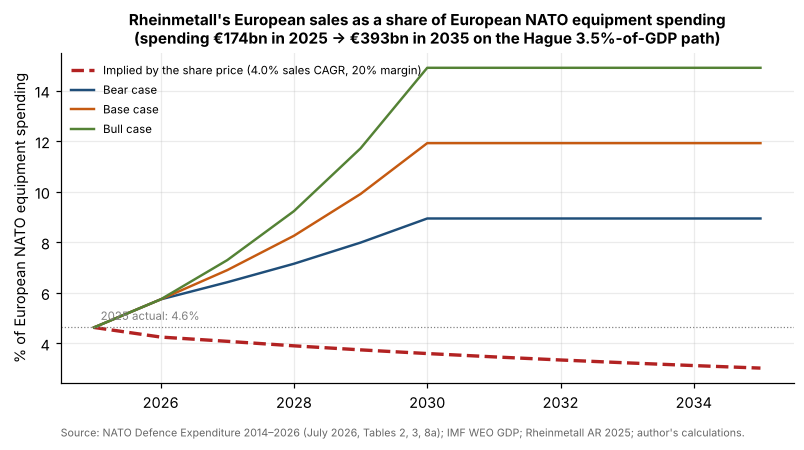

In [6]:
tot = R["budget"]
fig, ax = plt.subplots(figsize=(8.6, 3.9))
years = list(range(2025, 2036))
imp = pd.Series({y: M.SALES_2025 * (1 + R["a_cagr"]) ** (y - 2025) for y in years}) * M.EUR_SALES_SHARE_2025
ax.plot(years, imp / tot[years] * 100, color="#B22222", lw=2.2, ls="--", label=f"Implied by the share price ({R['a_cagr']:.1%} sales CAGR, 20% margin)")
for i, n in enumerate(["Bear", "Base", "Bull"]):
    s_ = pd.concat([pd.Series({2025: M.SALES_2025}), R["cases"][n][0]]) * M.EUR_SALES_SHARE_2025
    ax.plot(s_.index, s_ / tot[s_.index] * 100, color=PALETTE[i], lw=1.6, label=f"{n} case")
ax.axhline(R["tests"]["budget"]["today"] * 100, color="grey", lw=0.8, ls=":")
ax.text(2025.1, R["tests"]["budget"]["today"] * 100 + 0.3, f"2025 actual: {R['tests']['budget']['today']:.1%}", fontsize=7.5, color="grey")
ax.set_ylabel("% of European NATO equipment spending"); ax.legend(fontsize=7.5, loc="upper left")
ax.set_title(f"Rheinmetall's European sales as a share of European NATO equipment spending\n(spending €{tot[2025] / 1000:,.0f}bn in 2025 → €{tot[2035] / 1000:,.0f}bn in 2035 on the Hague 3.5%-of-GDP path)", fontsize=10)
source(ax, "Source: NATO Defence Expenditure 2014–2026 (July 2026, Tables 2, 3, 8a); IMF WEO GDP; Rheinmetall AR 2025; author's calculations.")
fig.savefig(FIG / "fig_budget.png"); plt.show()

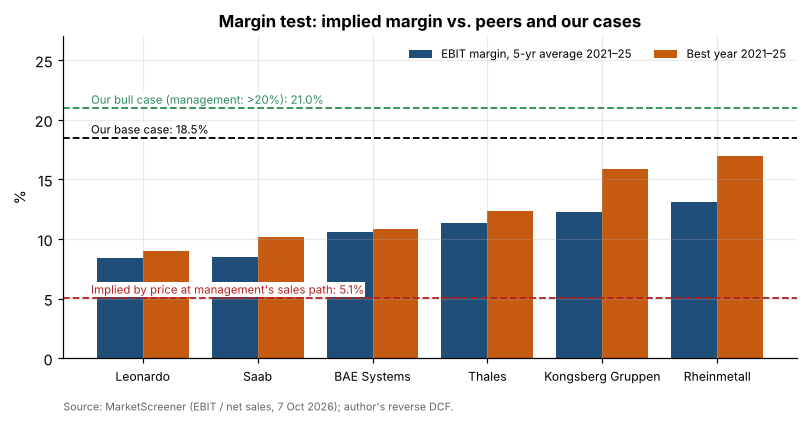

In [7]:
fig, ax = plt.subplots(figsize=(8.6, 3.8))
order = ["Leonardo", "Saab", "BAE Systems", "Thales", "Kongsberg Gruppen", "Rheinmetall"]
x = np.arange(len(order))
ax.bar(x - 0.2, PEERSTAT.loc[order, "5-yr average 2021–25"] * 100, 0.4, color=PALETTE[0], label="EBIT margin, 5-yr average 2021–25")
ax.bar(x + 0.2, PEERSTAT.loc[order, "Best year 2021–25"] * 100, 0.4, color=PALETTE[1], label="Best year 2021–25")
for val, lab, c in [(R["b_margin"], "Implied by price at management's sales path", "#B22222"), (0.185, "Our base case", "black"),
                    (0.21, "Our bull case (management: >20%)", "#2E8B57")]:
    ax.axhline(val * 100, color=c, ls="--", lw=1.2)
    ax.text(-0.45, val * 100 + 0.35, f"{lab}: {val:.1%}", fontsize=7.5, color=c, ha="left", bbox=dict(fc="white", ec="none", pad=0.5))
ax.set_xticks(x, order, fontsize=8); ax.set_ylabel("%"); ax.set_ylim(0, 27); ax.legend(fontsize=7.5, loc="upper right", ncol=2)
ax.set_title("Margin test: implied margin vs. peers and our cases")
source(ax, "Source: MarketScreener (EBIT / net sales, 7 Oct 2026); author's reverse DCF.")
fig.savefig(FIG / "fig_margins.png"); plt.show()

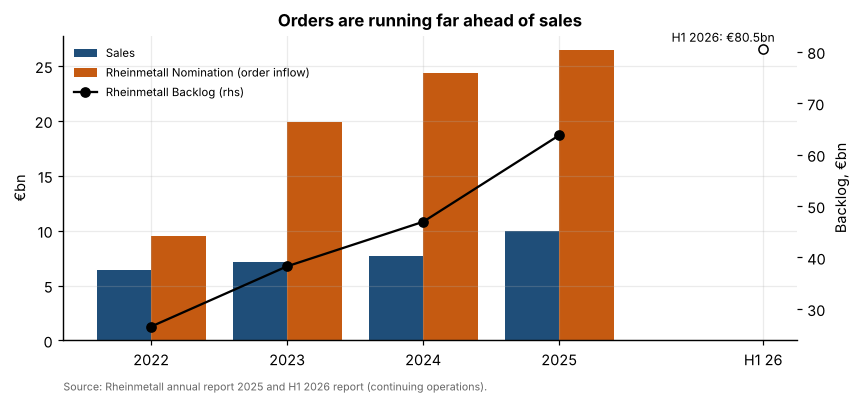

In [8]:
fig, ax = plt.subplots(figsize=(8.6, 3.6))
yrs = [2022, 2023, 2024, 2025]
ax.bar(np.array(yrs) - 0.2, H.loc["Sales", yrs] / 1000, 0.4, color=PALETTE[0], label="Sales")
ax.bar(np.array(yrs) + 0.2, H.loc["Rheinmetall Nomination", yrs] / 1000, 0.4, color=PALETTE[1], label="Rheinmetall Nomination (order inflow)")
ax2 = ax.twinx(); ax2.plot(yrs, H.loc["Rheinmetall Backlog", yrs] / 1000, color="black", marker="o", label="Rheinmetall Backlog (rhs)"); ax2.grid(False)
ax2.plot([2026.5], [80.467], "ko", mfc="white"); ax2.annotate("H1 2026: €80.5bn", (2026.5, 80.467), xytext=(-60, 5), textcoords="offset points", fontsize=8)
ax.set_ylabel("€bn"); ax2.set_ylabel("Backlog, €bn"); ax.set_xticks(yrs + [2026.5], [str(y) for y in yrs] + ["H1 26"])
h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels(); ax.legend(h1 + h2, l1 + l2, fontsize=7.5, loc="upper left")
ax.set_title("Orders are running far ahead of sales")
source(ax, "Source: Rheinmetall annual report 2025 and H1 2026 report (continuing operations).")
fig.savefig(FIG / "fig_backlog.png"); plt.show()

## Save

In [9]:
R["grid"].to_csv(DATA / "out_grid.csv"); R["wacc_sens"].to_csv(DATA / "out_wacc_sensitivity.csv")
pd.DataFrame({n: pd.concat([R["cases"][n][0].rename("Sales"), R["cases"][n][1].rename("Margin")], axis=1).stack() for n in R["cases"]}).to_csv(DATA / "out_cases.csv")
R["budget"].to_csv(DATA / "out_budget_eur.csv"); R["nato_check"].to_csv(DATA / "out_nato_ocr_check.csv"); PEERSTAT.to_csv(DATA / "out_peer_margins.csv")
json.dump({"mk": mk, "k": R["k"], "fx": R["fx"], "a_cagr": R["a_cagr"], "a_sales_2035": R["a_sales_2035"], "b_margin": R["b_margin"],
           "case_value": {n: v["per_share"] for n, v in R["case_val"].items()}, "case_ev": {n: v["ev"] for n, v in R["case_val"].items()},
           "implied_wacc": R["implied_wacc"], "tests": R["tests"]}, open(DATA / "out_results.json", "w"), indent=2, default=float)